Real-Time ML Inference REST API & Capstone

This notebook trains a small sentiment model, saves it as model.pkl, creates a FastAPI service, writes Docker and test files, and packages the complete GitHub-ready project.

Run every cell from top to bottom. At the end, download the ZIP file and upload its contents to a new GitHub repository.

Dataset note: this is a compact illustrative dataset for demonstrating the deployment workflow. Replace it with a larger labeled dataset for meaningful real-world performance.

1. Install and import dependencies

In [22]:
%pip -q install scikit-learn joblib fastapi uvicorn httpx pytest

In [23]:
import os, textwrap, zipfile, joblib
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

PROJECT_DIR = "/content/real_time_ml_api_capstone"
os.makedirs(PROJECT_DIR, exist_ok=True)
print("Project directory:", PROJECT_DIR)

Project directory: /content/real_time_ml_api_capstone


2. Prepare a labeled demonstration dataset

In [24]:
positive = [
"Absolutely loved this movie, the acting was brilliant.",
"A wonderful film with a clever script and excellent performances.",
"Fantastic from beginning to end, entertaining and beautifully made.",
"The cast was superb and the direction was thoughtful.",
"I enjoyed every minute, a delightful experience.",
"An inspiring story with great characters and emotional depth.",
"Funny, charming, and surprisingly heartwarming.",
"The cinematography was gorgeous and the soundtrack was excellent.",
"A brilliant film that kept me engaged throughout.",
"One of the best films I have watched this year.",
"Strong performances make this a highly enjoyable movie.",
"Beautiful storytelling and a satisfying ending.",
"This movie was entertaining, clever, and full of heart.",
"A moving masterpiece with unforgettable scenes.",
"Smart writing and wonderful acting made this film special.",
"I would happily watch this fantastic movie again.",
"The plot was engaging and the characters felt authentic.",
"An impressive achievement, both visually and emotionally.",
"Great dialogue, excellent direction, and a powerful story.",
"This was a delightful surprise and I highly recommend it."
]
negative = [
"I hated this movie, the acting was poor and the story was boring.",
"A terrible film with a weak script and disappointing performances.",
"Awful from beginning to end, dull and badly made.",
"The cast was unconvincing and the direction was messy.",
"I regret watching it, a tedious experience.",
"A confusing story with flat characters and no emotional depth.",
"Not funny, not charming, and painfully predictable.",
"The cinematography was dull and the soundtrack was annoying.",
"A disappointing film that failed to keep me engaged.",
"One of the worst films I have watched this year.",
"Weak performances make this an unpleasant movie.",
"Poor storytelling, terrible pacing, and an unsatisfying ending.",
"This movie was boring, predictable, and poorly written.",
"A forgettable mess with scenes that made no sense.",
"Lazy writing and wooden acting ruined this film.",
"I would never watch this terrible movie again.",
"The plot was confusing and the characters felt fake.",
"A frustrating failure, both visually and emotionally.",
"Bad dialogue, weak direction, and an unbelievable story.",
"This was a huge disappointment and I cannot recommend it."
]
df = pd.DataFrame({
    "text": positive + negative,
    "label": [1] * len(positive) + [0] * len(negative)
})
df["sentiment"] = df["label"].map({1: "positive", 0: "negative"})
display(df.sample(5, random_state=42))
print(df["sentiment"].value_counts())

,text,label,sentiment
19,This was a delightful surprise and I highly re...,1,positive
16,The plot was engaging and the characters felt ...,1,positive
15,I would happily watch this fantastic movie again.,1,positive
26,"Not funny, not charming, and painfully predict...",0,negative
4,"I enjoyed every minute, a delightful experience.",1,positive


sentiment
positive    20
negative    20
Name: count, dtype: int64


3. Train and evaluate the model

Test accuracy: 0.2
              precision    recall  f1-score   support

    negative       0.20      0.20      0.20         5
    positive       0.20      0.20      0.20         5

    accuracy                           0.20        10
   macro avg       0.20      0.20      0.20        10
weighted avg       0.20      0.20      0.20        10



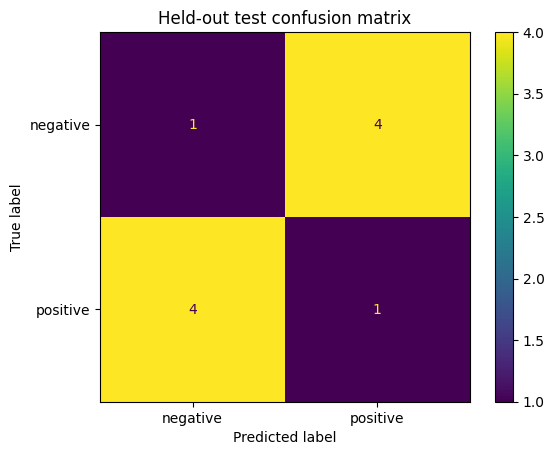

In [25]:
X_train, X_test, y_train, y_test = train_test_split(
    df["text"], df["label"], test_size=0.25,
    random_state=42, stratify=df["label"]
)

model = Pipeline([
    ("tfidf", TfidfVectorizer(lowercase=True, stop_words="english", ngram_range=(1, 2))),
    ("classifier", LogisticRegression(max_iter=1000, random_state=42))
])
model.fit(X_train, y_train)

predictions = model.predict(X_test)
print("Test accuracy:", round(accuracy_score(y_test, predictions), 3))
print(classification_report(y_test, predictions, target_names=["negative", "positive"], zero_division=0))
ConfusionMatrixDisplay.from_predictions(y_test, predictions, display_labels=["negative", "positive"])
plt.title("Held-out test confusion matrix")
plt.show()

4. Save the trained champion model

In [26]:
MODEL_PATH = os.path.join(PROJECT_DIR, "model.pkl")
joblib.dump(model, MODEL_PATH)
print("Saved model:", MODEL_PATH, "| size:", os.path.getsize(MODEL_PATH), "bytes")

Saved model: /content/real_time_ml_api_capstone/model.pkl | size: 8116 bytes


5. Create the FastAPI application

In [27]:
app_code = '''from pathlib import Path
import joblib
from fastapi import FastAPI, HTTPException
from pydantic import BaseModel, Field

MODEL_PATH = Path(__file__).parent / "model.pkl"
if not MODEL_PATH.exists():
    raise RuntimeError(f"Model file not found: {MODEL_PATH}")
model = joblib.load(MODEL_PATH)

app = FastAPI(title="Sentiment Prediction API",
              description="Real-time positive/negative text inference API",
              version="1.0.0")

class PredictionRequest(BaseModel):
    text: str = Field(..., min_length=1, max_length=5000)

class PredictionResponse(BaseModel):
    text: str
    predicted_label: str
    probabilities: dict[str, float]

@app.get("/")
def root():
    return {"message": "Sentiment API is running", "docs": "/docs"}

@app.get("/health")
def health():
    return {"status": "ok", "model_loaded": True}

@app.post("/predict", response_model=PredictionResponse)
def predict(request: PredictionRequest):
    text = request.text.strip()
    if not text:
        raise HTTPException(status_code=422, detail="Text must not be empty")
    prediction = int(model.predict([text])[0])
    probs = model.predict_proba([text])[0]
    probabilities = {
        ("negative" if int(label) == 0 else "positive"): round(float(prob), 6)
        for label, prob in zip(model.classes_, probs)
    }
    return {
        "text": text,
        "predicted_label": "positive" if prediction == 1 else "negative",
        "probabilities": probabilities,
    }
'''
with open(os.path.join(PROJECT_DIR, "app.py"), "w") as f:
    f.write(app_code)
print(open(os.path.join(PROJECT_DIR, "app.py")).read()[:500])

from pathlib import Path
import joblib
from fastapi import FastAPI, HTTPException
from pydantic import BaseModel, Field

MODEL_PATH = Path(__file__).parent / "model.pkl"
if not MODEL_PATH.exists():
    raise RuntimeError(f"Model file not found: {MODEL_PATH}")
model = joblib.load(MODEL_PATH)

app = FastAPI(title="Sentiment Prediction API",
              description="Real-time positive/negative text inference API",
              version="1.0.0")

class PredictionRequest(BaseModel):
    text: str =


6. Add pinned dependencies, Dockerfile, tests, and documentation

In [28]:
requirements_text = '''fastapi==0.115.12
uvicorn[standard]==0.34.0
scikit-learn==1.6.1
joblib==1.4.2
pydantic==2.10.6
httpx==0.28.1
pytest==8.3.5
'''
dockerfile_text = '''FROM python:3.11-slim
WORKDIR /app
COPY requirements.txt .
RUN pip install --no-cache-dir -r requirements.txt
COPY app.py model.pkl ./
EXPOSE 8000
CMD ["uvicorn", "app:app", "--host", "0.0.0.0", "--port", "8000"]
'''
tests_text = '''from fastapi.testclient import TestClient
from app import app

client = TestClient(app)

def test_root():
    response = client.get("/")
    assert response.status_code == 200
    assert response.json()["docs"] == "/docs"

def test_health():
    response = client.get("/health")
    assert response.status_code == 200
    assert response.json()["model_loaded"] is True

def test_predict():
    response = client.post("/predict", json={"text": "A wonderful and enjoyable film"})
    assert response.status_code == 200
    body = response.json()
    assert body["predicted_label"] in ["positive", "negative"]
    assert set(body["probabilities"]) == {"positive", "negative"}

def test_empty_text():
    response = client.post("/predict", json={"text": "   "})
    assert response.status_code == 422
'''
readme_text = '''# Real-Time ML Inference REST API & Capstone

A sentiment classification model served as a REST API using FastAPI.

## Files
- app.py: FastAPI service with /predict and /health endpoints
- model.pkl: trained TF-IDF and Logistic Regression pipeline
- requirements.txt: pinned dependencies
- Dockerfile: container build instructions
- test_app.py: API unit tests

## Run locally
```bash
python -m venv .venv
source .venv/bin/activate  # Windows: .venv\\Scripts\\activate
pip install -r requirements.txt
uvicorn app:app --reload
```
Open http://127.0.0.1:8000/docs.

## Example request
```bash
curl -X POST http://127.0.0.1:8000/predict -H "Content-Type: application/json" -d '{"text":"The acting was wonderful"}'
```

## Tests
```bash
pytest -v
```

## Docker
```bash
docker build -t sentiment-api .
docker run --rm -p 8000:8000 sentiment-api
```

## Architecture
Client JSON -> FastAPI validation -> saved TF-IDF/logistic-regression pipeline -> prediction and class probabilities -> JSON response.

## Dataset limitation
The notebook uses a small illustrative dataset for a reproducible demonstration. Replace it with a larger representative labeled dataset before claiming real-world performance.
'''
files = {
    "requirements.txt": requirements_text,
    "Dockerfile": dockerfile_text,
    "test_app.py": tests_text,
    "README.md": readme_text,
}
for filename, content in files.items():
    with open(os.path.join(PROJECT_DIR, filename), "w") as f:
        f.write(content)
print("Created:", ", ".join(files.keys()))

Created: requirements.txt, Dockerfile, test_app.py, README.md


7. Test the API

In [29]:
from fastapi.testclient import TestClient
import importlib.util, sys

sys.path.insert(0, PROJECT_DIR)
spec = importlib.util.spec_from_file_location("capstone_app", os.path.join(PROJECT_DIR, "app.py"))
api_module = importlib.util.module_from_spec(spec)
spec.loader.exec_module(api_module)
client = TestClient(api_module.app)

print("GET /:", client.get("/").json())
print("GET /health:", client.get("/health").json())
response = client.post("/predict", json={"text": "The acting was wonderful and the story was exciting"})
print("POST /predict status:", response.status_code)
print("Prediction:", response.json())
assert response.status_code == 200
assert set(response.json()["probabilities"]) == {"positive", "negative"}
print("API smoke test passed.")

GET /: {'message': 'Sentiment API is running', 'docs': '/docs'}
GET /health: {'status': 'ok', 'model_loaded': True}
POST /predict status: 200
Prediction: {'text': 'The acting was wonderful and the story was exciting', 'predicted_label': 'positive', 'probabilities': {'negative': 0.489203, 'positive': 0.510797}}
API smoke test passed.


8. Package the complete GitHub-ready project

In [30]:
ZIP_PATH = "/content/real_time_ml_api_capstone.zip"
with zipfile.ZipFile(ZIP_PATH, "w", zipfile.ZIP_DEFLATED) as archive:
    for filename in os.listdir(PROJECT_DIR):
        full_path = os.path.join(PROJECT_DIR, filename)
        if os.path.isfile(full_path):
            archive.write(full_path, arcname=f"real_time_ml_api_capstone/{filename}")

print("Project files:")
for filename in sorted(os.listdir(PROJECT_DIR)):
    print(" -", filename)
print("\\nZIP ready:", ZIP_PATH)

Project files:
 - Dockerfile
 - README.md
 - __pycache__
 - app.py
 - model.pkl
 - requirements.txt
 - test_app.py
\nZIP ready: /content/real_time_ml_api_capstone.zip


9. Download your ZIP file

In [31]:
from google.colab import files
files.download(ZIP_PATH)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>